# Flight Delay Prediction Using Airline Operations Data Original Kaggle Records ONLY

**Student:** Abdulla Ali Beer &nbsp; | &nbsp; **Student ID:** 10409785  
**University:** Emirates Aviation University &nbsp; | &nbsp; **Unit:** EAM04DS / Machine Learning




## 0. Settings and dependencies


In [1]:
from __future__ import annotations
from pathlib import Path
import json, os, sys, time, importlib.util, subprocess, hashlib, shutil, warnings

SEED = 42
DATASET_ID = 'arvindnagaonkar/flight-delay/versions/2'  # verified Kaggle version 2
SOURCE_FILE = 'Flight_Delay.parquet'
LOCAL_PARQUET = None  # For an already downloaded ORIGINAL file: '/path/to/Flight_Delay.parquet'
SAMPLE_PER_YEAR = 30000  # 6 years -> up to 180,000 real sampled rows; set higher with more RAM
RUN_FAST = False  # True = fewer model estimators for faster *real-data* runs (NEVER synthetic)
OUT = Path('REAL_KAGGLE_flight_results')
OUT.mkdir(exist_ok=True, parents=True)

# First-run notebook installation of genuine public Python packages.
required = {'numpy':'numpy','pandas':'pandas','pyarrow':'pyarrow','sklearn':'scikit-learn',
            'xgboost':'xgboost','matplotlib':'matplotlib','joblib':'joblib','kagglehub':'kagglehub'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing required packages:',missing)
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score,recall_score,f1_score,fbeta_score,roc_auc_score,
                             average_precision_score,confusion_matrix,precision_recall_curve,
                             roc_curve,brier_score_loss,ConfusionMatrixDisplay,classification_report)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import kagglehub
rng = np.random.default_rng(SEED)
print('Python:',sys.version.split()[0], '| pandas:',pd.__version__, '| sklearn:',__import__('sklearn').__version__)
print('SOURCE LOCKED:',DATASET_ID,'/',SOURCE_FILE)

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
SOURCE LOCKED: arvindnagaonkar/flight-delay/versions/2 / Flight_Delay.parquet


## 1. Acquire the exact real Kaggle Parquet file


In [2]:
def acquire_original_file():
    possible = []
    if LOCAL_PARQUET:
        possible.append(Path(LOCAL_PARQUET))
    possible += [Path('Flight_Delay.parquet'),
                 Path('/kaggle/input/flight-delay/Flight_Delay.parquet')]
    for path in possible:
        if path.is_file():
            print('Reusing original Kaggle file:',path.resolve())
            return path.resolve()
    print('Downloading genuine data from Kaggle (approx. 772 MB). This requires Internet access.')
    try:
        obtained = Path(kagglehub.dataset_download(DATASET_ID, path=SOURCE_FILE))
    except Exception as e:
        raise RuntimeError(
            'Cannot download original data in this runtime. Run the notebook in Colab/Kaggle with '
            'Internet enabled, OR manually download the ORIGINAL `Flight_Delay.parquet` from '
            'https://www.kaggle.com/datasets/arvindnagaonkar/flight-delay and set LOCAL_PARQUET. '
            'No replacement or synthetic data will be used. Kaggle error: '+str(e)) from e
    if obtained.is_file():
        path=obtained
    elif obtained.is_dir():
        matches=list(obtained.rglob(SOURCE_FILE))
        if not matches: raise FileNotFoundError(f'Kaggle download returned {obtained}, but {SOURCE_FILE} was not found')
        path=matches[0]
    else: raise FileNotFoundError('Kaggle returned a nonexistent path: '+str(obtained))
    if path.name != SOURCE_FILE:
        raise ValueError(f'Unexpected Kaggle file {path.name}, expected {SOURCE_FILE}')
    return path.resolve()

SOURCE_PATH=acquire_original_file()
assert SOURCE_PATH.suffix.lower()=='.parquet'
assert SOURCE_PATH.stat().st_size > 100_000_000, 'File unexpectedly small; check that you have the full original Parquet file.'
print('ORIGINAL_FILE:',SOURCE_PATH)
print('SIZE_MB:',round(SOURCE_PATH.stat().st_size/1e6,2))

100%|██████████| 546M/546M [00:04<00:00, 129MB/s]

Extracting zip of Flight_Delay.parquet...


ORIGINAL_FILE: /root/.cache/kagglehub/datasets/arvindnagaonkar/flight-delay/versions/2/Flight_Delay.parquet
SIZE_MB: 772.2


## 2. Inspect original schema; sample REAL records in bounded memory


In [3]:
ALIASES={
 'date':['FlightDate','FL_DATE','Flight_Date','flight_date'],
 'airline':['Marketing_Airline_Network','Reporting_Airline','Airline','OP_UNIQUE_CARRIER','OP_CARRIER'],
 'origin':['Origin','ORIGIN','OriginCityName','OriginAirport','OriginAirportID'],
 'dest':['Dest','DEST','DestCityName','DestAirport','DestAirportID'],
 'dep_schedule':['CRSDepTime','CRS_DEP_TIME'],
 'arr_schedule':['CRSArrTime','CRS_ARR_TIME'],
 'elapsed_schedule':['CRSElapsedTime','CRS_ELAPSED_TIME'],
 'distance':['Distance','DISTANCE'],
 'arr_delay':['ArrDelay','ARR_DELAY'],
 'cancelled':['Cancelled','CANCELLED'],
 'diverted':['Diverted','DIVERTED'],
}
reader=pq.ParquetFile(SOURCE_PATH)
original_columns=reader.schema_arrow.names
name_lookup={c.lower():c for c in original_columns}
selected={key:next((name_lookup[c.lower()] for c in options if c.lower() in name_lookup),None)
          for key,options in ALIASES.items()}
required_fields=['date','airline','origin','dest','dep_schedule','arr_schedule','elapsed_schedule','distance','arr_delay']
missing_fields=[k for k in required_fields if selected[k] is None]
print('Real source schema (first 45 columns):', original_columns[:45])
print('Selected actual source fields:', selected)
print('Parquet metadata row count:',reader.metadata.num_rows)
if missing_fields:
    raise ValueError(f'Required original Kaggle fields absent: {missing_fields}; available fields: {original_columns}')
selected_columns=list(dict.fromkeys(v for v in selected.values() if v is not None))

def parse_flight_dates(s):
    # Parquet can supply timestamps or yyyy-mm-dd strings or integer YYYYMMDD.
    if pd.api.types.is_datetime64_any_dtype(s):
        return pd.to_datetime(s,errors='coerce')
    strings=s.astype('string').str.strip()
    dates=pd.to_datetime(strings,errors='coerce',format='mixed')
    # Older pandas support or unusual date layouts: retry 8-digit YYYYMMDD explicitly.
    mask8=strings.str.fullmatch(r'\d{8}').fillna(False)
    if bool(mask8.any()):
        dates.loc[mask8]=pd.to_datetime(strings.loc[mask8],format='%Y%m%d',errors='coerce')
    return dates

seen_by_year={}
bags={}
count_scanned=0
start=time.time()
for batch_id,batch in enumerate(reader.iter_batches(batch_size=100000,columns=selected_columns,use_threads=True),start=1):
    b=batch.to_pandas()
    b=b.rename(columns={raw:canon for canon,raw in selected.items() if raw is not None})
    b['date']=parse_flight_dates(b['date'])
    b=b.loc[b['date'].notna()].copy()
    b=b.loc[b.date.dt.year.between(2018,2023)]
    b['arr_delay']=pd.to_numeric(b['arr_delay'],errors='coerce')
    b=b.loc[b.arr_delay.notna()].copy()  # incomplete / non-evaluable flights excluded
    for flag in ['cancelled','diverted']:
        if flag in b.columns:
            b=b.loc[pd.to_numeric(b[flag],errors='coerce').fillna(0).eq(0)]
    b=b.loc[b['airline'].notna() & b['origin'].notna() & b['dest'].notna()]
    if b.empty: continue
    b['year']=b.date.dt.year
    count_scanned+=len(b)
    b['sample_key']=rng.random(len(b))
    for yr, group in b.groupby('year',sort=True):
        yr=int(yr)
        seen_by_year[yr]=seen_by_year.get(yr,0)+len(group)
        union=pd.concat([bags[yr],group],ignore_index=True) if yr in bags else group
        bags[yr]=union.nsmallest(SAMPLE_PER_YEAR,'sample_key').reset_index(drop=True)
    if batch_id%40==0:
        print('Processed',f'{batch_id:,}','Parquet batches; eligible rows:',f'{count_scanned:,}',
              '| sample sizes:',{y:len(v) for y,v in bags.items()})
if not bags:raise RuntimeError('Original Parquet contains no eligible completed flights.')
raw=pd.concat([v.drop(columns='sample_key') for y,v in sorted(bags.items())],ignore_index=True)
assert len(raw)>1000
print('Genuine flight rows scanned:',f'{reader.metadata.num_rows:,}',
      '| eligible:',f'{count_scanned:,}','| analyzed:',f'{len(raw):,}')
print('Available years:',sorted(seen_by_year))
print('Eligible original records by year:',seen_by_year)
print('Random sample by year:',raw.year.value_counts().sort_index().to_dict())
print('Real-data load duration (seconds):',round(time.time()-start,1))

Real source schema (first 45 columns): ['Year', 'Month', 'DayofMonth', 'FlightDate', 'Marketing_Airline_Network', 'OriginCityName', 'DestCityName', 'CRSDepTime', 'DepTime', 'DepDelay', 'DepDelayMinutes', 'TaxiOut', 'WheelsOff', 'WheelsOn', 'TaxiIn', 'CRSArrTime', 'ArrTime', 'ArrDelay', 'ArrDelayMinutes', 'CRSElapsedTime', 'ActualElapsedTime', 'AirTime', 'Distance', 'DistanceGroup', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay', '__index_level_0__']
Selected actual source fields: {'date': 'FlightDate', 'airline': 'Marketing_Airline_Network', 'origin': 'OriginCityName', 'dest': 'DestCityName', 'dep_schedule': 'CRSDepTime', 'arr_schedule': 'CRSArrTime', 'elapsed_schedule': 'CRSElapsedTime', 'distance': 'Distance', 'arr_delay': 'ArrDelay', 'cancelled': None, 'diverted': None}
Parquet metadata row count: 30132672
Processed 40 Parquet batches; eligible rows: 4,000,000 | sample sizes: {2018: 30000}
Processed 80 Parquet batches; eligible rows: 8,000,000 | sam

## 3. Target definition, leakage prevention and feature engineering


In [4]:
df=raw.copy()
df['target']=(df.arr_delay >=15).astype('int8')
df['month']=df.date.dt.month.astype('int16')
df['weekday']=df.date.dt.dayofweek.astype('int16')
df['weekend']=(df.weekday>=5).astype('int16')
def hhmm_to_hour(s):
    numeric=pd.to_numeric(s,errors='coerce')
    # hhmm scheduled time; 2400 means next-day midnight; x % 100 must be < 60
    good=numeric.notna() & (numeric>=0) & (numeric<=2400) & ((numeric%100)<60)
    return ((numeric.where(good)//100)%24).astype('float32')
df['dep_hour']=hhmm_to_hour(df.dep_schedule)
df['arr_hour']=hhmm_to_hour(df.arr_schedule)
for c in ['elapsed_schedule','distance']:
    df[c]=pd.to_numeric(df[c],errors='coerce').astype('float32')
    df.loc[df[c]<0,c]=np.nan
for c in ['airline','origin','dest']:
    df[c]=df[c].astype('string').str.strip().fillna('MISSING').replace('', 'MISSING').astype(str)
df['route']=(df['origin']+'->'+df['dest'])
for c in ['dep_hour','arr_hour']:
    df[c+'_sin']=np.sin(2*np.pi*df[c]/24)
    df[c+'_cos']=np.cos(2*np.pi*df[c]/24)
NUM_COLS=['month','weekday','weekend','dep_hour_sin','dep_hour_cos','arr_hour_sin','arr_hour_cos',
          'elapsed_schedule','distance']
CAT_COLS=['airline','origin','dest','route']
FEATURES=NUM_COLS+CAT_COLS
PROHIBITED={'arr_delay','arrtime','deptime','depdelay','taxiout','taxiin','wheelsOff',
            'actualelapsedtime','carrierdelay','weatherdelay','nasdelay','securitydelay',
            'lateaircraftdelay','target'}
assert not any(c.lower() in {x.lower() for x in PROHIBITED} for c in FEATURES)
assert 2023 in set(df.year), 'The original source has no 2023 rows; cannot perform proposed holdout.'
train=df[df.year <=2021].sort_values('date').copy()
valid=df[df.year ==2022].sort_values('date').copy()
test=df[df.year ==2023].sort_values('date').copy()
if min(len(train),len(valid),len(test)) < 500:
    raise RuntimeError('Insufficient rows in chronological train/valid/test partitions.')
if any(p.target.nunique()!=2 for p in [train,valid,test]):
    raise RuntimeError('At least one chronological split has only one target class.')
X_train,y_train=train[FEATURES],train['target']
X_val,y_val=valid[FEATURES],valid['target']
X_test,y_test=test[FEATURES],test['target']
print('Training: 2018–2021',len(train),'delay rate:',round(y_train.mean(),4))
print('Validation: 2022',len(valid),'delay rate:',round(y_val.mean(),4))
print('Test: 2023 (dataset ends in April)',len(test),'delay rate:',round(y_test.mean(),4))
print('Missingness by predictor:',(df[FEATURES].isna().mean()*100).round(2).to_dict())
assert train.date.max() < valid.date.min() < test.date.min()

Training: 2018–2021 120000 delay rate: 0.1923
Validation: 2022 30000 delay rate: 0.249
Test: 2023 (dataset ends in April) 30000 delay rate: 0.2673
Missingness by predictor: {'month': 0.0, 'weekday': 0.0, 'weekend': 0.0, 'dep_hour_sin': 0.0, 'dep_hour_cos': 0.0, 'arr_hour_sin': 0.0, 'arr_hour_cos': 0.0, 'elapsed_schedule': 0.0, 'distance': 0.0, 'airline': 0.0, 'origin': 0.0, 'dest': 0.0, 'route': 0.0}


## 4. Original-data exploratory analysis


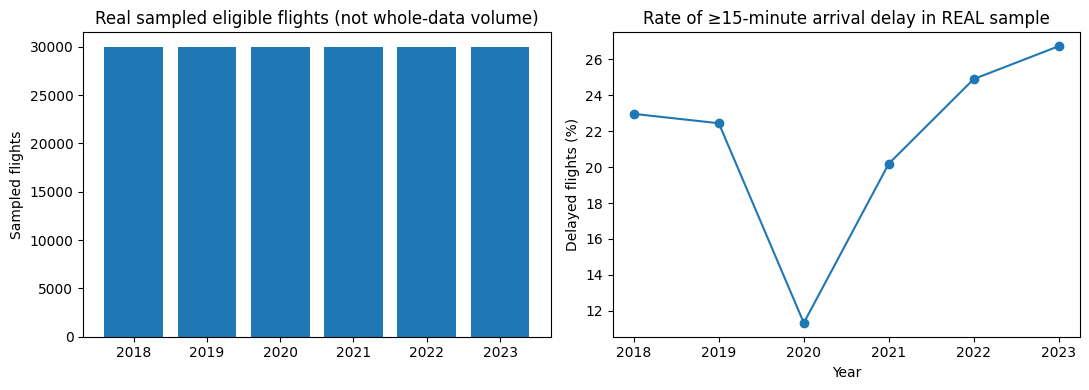

In [5]:
annual=df.groupby('year',as_index=False).agg(sample_n=('target','size'),delay_fraction=('target','mean'))
monthly=df.groupby(['year','month'],as_index=False).agg(sample_n=('target','size'),delay_fraction=('target','mean'))
annual.to_csv(OUT/'annual_real_sample_summary.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar(annual.year.astype(str),annual.sample_n)
axs[0].set(title='Real sampled eligible flights (not whole-data volume)',ylabel='Sampled flights')
axs[1].plot(annual.year,annual.delay_fraction*100,marker='o')
axs[1].set(title='Rate of ≥15-minute arrival delay in REAL sample',ylabel='Delayed flights (%)',xlabel='Year')
fig.tight_layout();fig.savefig(OUT/'01_real_annual_sample.png',dpi=170);plt.show()

## 5. Three proposed algorithms, transparent model selection

In [6]:
def build_preprocessor(scaled):
    numeric=Pipeline([('impute',SimpleImputer(strategy='median'))] +
                     ([('scale',StandardScaler())] if scaled else []))
    categorical=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                          ('onehot',OneHotEncoder(handle_unknown='ignore',min_frequency=50))])
    return ColumnTransformer([('numeric',numeric,NUM_COLS),('categorical',categorical,CAT_COLS)],
                             remainder='drop',sparse_threshold=0.4)

weight_ratio=max(1.0, float((y_train==0).sum())/max(1,int((y_train==1).sum())))
rf_n=80 if RUN_FAST else 150
xgb_n=100 if RUN_FAST else 250
model_specs={
 'Logistic Regression':[(dict(C=c),LogisticRegression(C=c,max_iter=650,class_weight='balanced',
                                      solver='liblinear',random_state=SEED),True) for c in [0.3,1.0]],
 'Random Forest':[(dict(max_depth=d),RandomForestClassifier(n_estimators=rf_n,max_depth=d,
                          min_samples_leaf=8,class_weight='balanced_subsample',
                          n_jobs=-1,random_state=SEED),False) for d in [12,22]],
 'XGBoost':[(dict(max_depth=d),XGBClassifier(n_estimators=xgb_n,max_depth=d,
                          learning_rate=0.055,subsample=0.85,colsample_bytree=0.85,
                          scale_pos_weight=weight_ratio,objective='binary:logistic',
                          eval_metric='logloss',tree_method='hist',importance_type='gain',
                          n_jobs=4,random_state=SEED),False) for d in [3,5]]
}
models={}; valid_scores={}; val_probs={}; tuning_rows=[]
for family,candidates in model_specs.items():
    best_score=-np.inf
    for configuration,estimator,scaled in candidates:
        t0=time.perf_counter()
        pipe=Pipeline([('preprocessing',build_preprocessor(scaled)),('model',estimator)])
        pipe.fit(X_train,y_train)
        probs=pipe.predict_proba(X_val)[:,1]
        ap=float(average_precision_score(y_val,probs))
        ra=float(roc_auc_score(y_val,probs))
        tuning_rows.append({'model':family,'configuration':json.dumps(configuration),
                            'validation_pr_auc':ap,'validation_roc_auc':ra,
                            'elapsed_seconds':round(time.perf_counter()-t0,2)})
        print(f'{family} {configuration} validation PR-AUC={ap:.4f} ROC-AUC={ra:.4f}')
        if ap>best_score:
            best_score=ap
            models[family]=pipe
            val_probs[family]=probs
            valid_scores[family]=ap
pd.DataFrame(tuning_rows).to_csv(OUT/'validation_hyperparameter_results.csv',index=False)
# No tuning or model choice uses test performance.
champion=max(valid_scores,key=valid_scores.get)
print('MODEL SELECTED ON 2022 VALIDATION ONLY:',champion,'PR-AUC:',valid_scores[champion])

Logistic Regression {'C': 0.3} validation PR-AUC=0.3452 ROC-AUC=0.6296
Logistic Regression {'C': 1.0} validation PR-AUC=0.3432 ROC-AUC=0.6274
Random Forest {'max_depth': 12} validation PR-AUC=0.3632 ROC-AUC=0.6427
Random Forest {'max_depth': 22} validation PR-AUC=0.3764 ROC-AUC=0.6484
XGBoost {'max_depth': 3} validation PR-AUC=0.3771 ROC-AUC=0.6520
XGBoost {'max_depth': 5} validation PR-AUC=0.3782 ROC-AUC=0.6508
MODEL SELECTED ON 2022 VALIDATION ONLY: XGBoost PR-AUC: 0.3782468417537532


## 6. Determine recall-oriented classification threshold

In [7]:
def choose_f2_threshold(y_true,prob):
    pr,rec,thresholds=precision_recall_curve(y_true,prob)
    # pr,rec have N+1 points; thresholds N.
    if not len(thresholds):return 0.5
    beta2=4.0
    f2=(1+beta2)*pr[:-1]*rec[:-1]/np.maximum(beta2*pr[:-1]+rec[:-1],1e-12)
    # Very small thresholds can produce large numbers of false positives; F2 quantifies this tradeoff.
    return float(thresholds[int(np.nanargmax(f2))])
thresholds={name:choose_f2_threshold(y_val.to_numpy(),v) for name,v in val_probs.items()}
print('Decision thresholds optimized on genuine 2022 validation:',
      {k:round(v,5) for k,v in thresholds.items()})

Decision thresholds optimized on genuine 2022 validation: {'Logistic Regression': 0.10829, 'Random Forest': 0.35746, 'XGBoost': 0.29132}


## 7. Genuine unseen-2023 results: PR-AUC, ROC-AUC, Precision, Recall, F1, F2, confusion matrix


In [8]:
def evaluate(y_true,prob,threshold):
    y_true=np.asarray(y_true,dtype=int); prob=np.asarray(prob,dtype=float)
    labels=(prob>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,labels,labels=[0,1]).ravel()
    return {'n_test':int(len(y_true)), 'prevalence':float(y_true.mean()),
            'precision':float(precision_score(y_true,labels,zero_division=0)),
            'recall':float(recall_score(y_true,labels,zero_division=0)),
            'f1':float(f1_score(y_true,labels,zero_division=0)),
            'f2':float(fbeta_score(y_true,labels,beta=2,zero_division=0)),
            'pr_auc':float(average_precision_score(y_true,prob)),
            'roc_auc':float(roc_auc_score(y_true,prob)),
            'brier':float(brier_score_loss(y_true,prob)),
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
test_predictions={}
rows=[]
baseline_prob=np.repeat(y_train.mean(),len(y_test))
rows.append({'model':'Dummy constant training prevalence','validation_pr_auc':float(y_val.mean()),
             'threshold':0.5,**evaluate(y_test,baseline_prob,0.5)})
for family,model in models.items():
    p=model.predict_proba(X_test)[:,1]
    test_predictions[family]=p
    rows.append({'model':family,'validation_pr_auc':valid_scores[family],
                 'threshold':thresholds[family],**evaluate(y_test,p,thresholds[family])})
test_metrics=pd.DataFrame(rows)
test_metrics.to_csv(OUT/'real_kaggle_2023_test_metrics.csv',index=False)
print('\nTEST RESULTS — ORIGINAL ARVIND NAGAONKAR FLIGHT_DELAY.PARQUET — REAL FLIGHTS')
print(test_metrics.round(4).to_string(index=False))
print('PRESELECTED CHAMPION:',champion)
print(classification_report(y_test,test_predictions[champion]>=thresholds[champion],
                            target_names=['On-time (<15m)','Delayed (>=15m)'],zero_division=0))


TEST RESULTS — ORIGINAL ARVIND NAGAONKAR FLIGHT_DELAY.PARQUET — REAL FLIGHTS
                             model  validation_pr_auc  threshold  n_test  prevalence  precision  recall     f1     f2  pr_auc  roc_auc  brier    tn    fp   fn   tp
Dummy constant training prevalence             0.2490     0.5000   30000      0.2673     0.0000  0.0000 0.0000 0.0000  0.2673   0.5000 0.2015 21981     0 8019    0
               Logistic Regression             0.3452     0.1083   30000      0.2673     0.2674  0.9998 0.4219 0.6459  0.3605   0.6192 0.2359    16 21965    2 8017
                     Random Forest             0.3764     0.3575   30000      0.2673     0.2780  0.9726 0.4324 0.6485  0.3720   0.6283 0.2316  1729 20252  220 7799
                           XGBoost             0.3782     0.2913   30000      0.2673     0.2762  0.9732 0.4302 0.6467  0.3522   0.6142 0.2269  1525 20456  215 7804
PRESELECTED CHAMPION: XGBoost
                 precision    recall  f1-score   support

 On-time (<15m

## 8. Graphs and interpretation real 2023

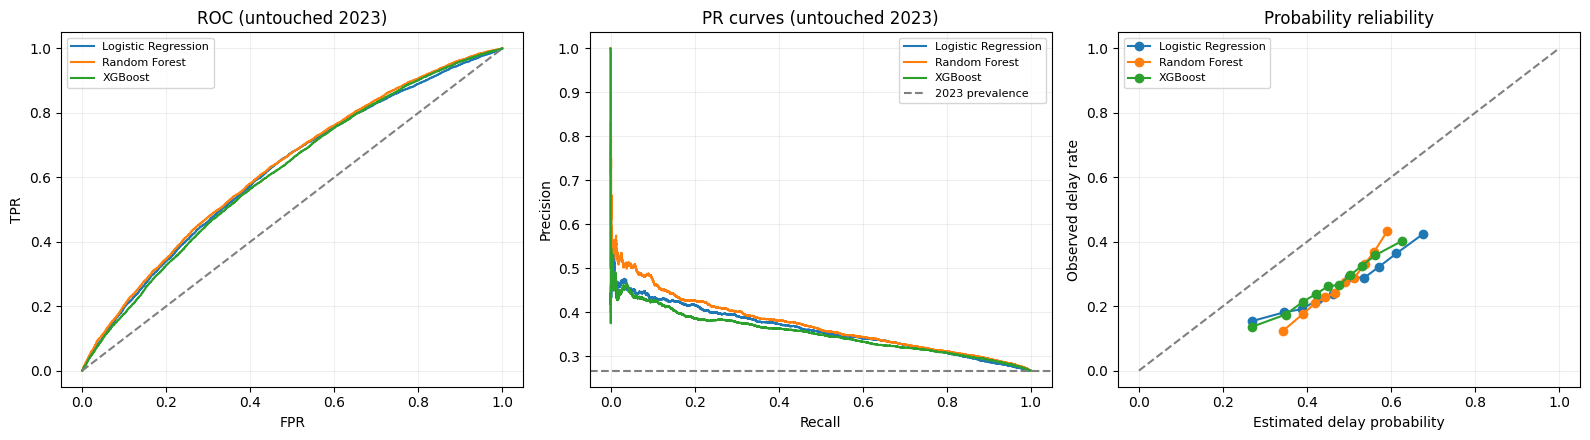

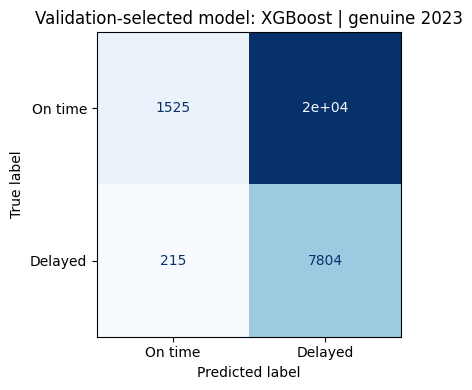

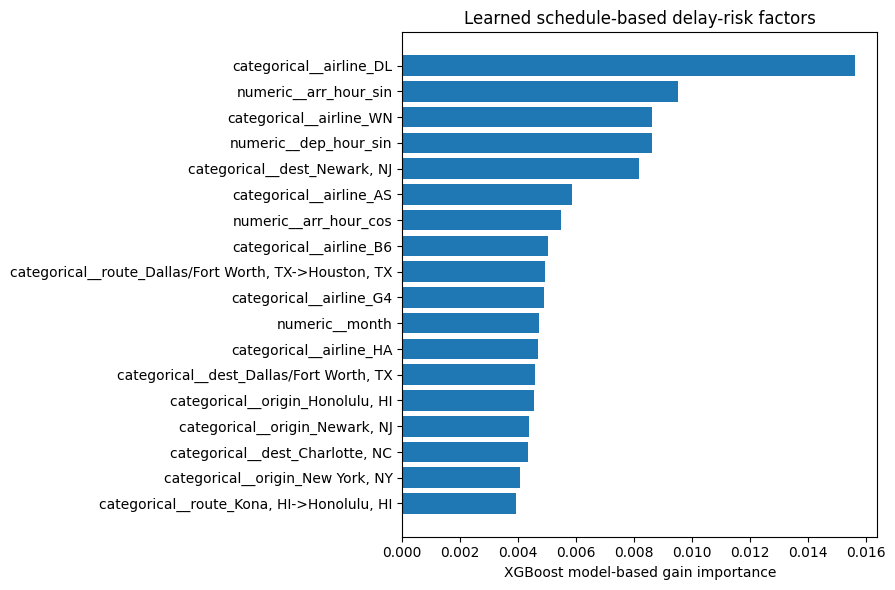

2023 monthly stability:
  month_2023    n  delay_rate  recall  pr_auc
          1 7346       0.273   0.985   0.349
          2 7055       0.226   0.991   0.319
          3 7909       0.283   0.957   0.390
          4 7690       0.283   0.966   0.417


In [9]:
fig,axs=plt.subplots(1,3,figsize=(16,4.5))
for name,p in test_predictions.items():
    fpr,tpr,_=roc_curve(y_test,p)
    prs,rc,_=precision_recall_curve(y_test,p)
    observed,estimated=calibration_curve(y_test,p,n_bins=10,strategy='quantile')
    axs[0].plot(fpr,tpr,label=name)
    axs[1].plot(rc,prs,label=name)
    axs[2].plot(estimated,observed,marker='o',label=name)
axs[0].plot([0,1],[0,1],ls='--',color='gray')
axs[1].axhline(y_test.mean(),ls='--',color='gray',label='2023 prevalence')
axs[2].plot([0,1],[0,1],ls='--',color='gray')
axs[0].set(title='ROC (untouched 2023)',xlabel='FPR',ylabel='TPR')
axs[1].set(title='PR curves (untouched 2023)',xlabel='Recall',ylabel='Precision')
axs[2].set(title='Probability reliability',xlabel='Estimated delay probability',ylabel='Observed delay rate')
for ax in axs:ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'02_roc_pr_calibration_REAL.png',dpi=165);plt.show()
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,
    test_predictions[champion]>=thresholds[champion],
    labels=[0,1],display_labels=['On time','Delayed'],
    cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Validation-selected model: '+champion+' | genuine 2023')
fig.tight_layout();fig.savefig(OUT/'03_confusion_matrix_REAL.png',dpi=170);plt.show()
# XGBoost feature importance is associational, not an identified cause of delay.
xgb=models['XGBoost']
features=xgb.named_steps['preprocessing'].get_feature_names_out()
importance=xgb.named_steps['model'].feature_importances_
ix=np.argsort(importance)[-18:]
fig,ax=plt.subplots(figsize=(9,6))
ax.barh(np.array(features)[ix],np.array(importance)[ix])
ax.set(xlabel='XGBoost model-based gain importance',title='Learned schedule-based delay-risk factors')
fig.tight_layout();fig.savefig(OUT/'04_xgboost_feature_importance_REAL.png',dpi=170);plt.show()
# Month-by-month holdout stability: note the 2023 period is only Jan–Apr.
stability=[]
for month,g in test.groupby('month'):
    idx=np.flatnonzero(test.month.to_numpy()==month)
    yy=y_test.to_numpy()[idx];pp=test_predictions[champion][idx]
    stability.append({'month_2023':int(month),'n':len(idx),'delay_rate':float(yy.mean()),
       'recall':float(recall_score(yy,pp>=thresholds[champion],zero_division=0)),
       'pr_auc':float(average_precision_score(yy,pp)) if yy.sum()>0 else np.nan})
pd.DataFrame(stability).to_csv(OUT/'monthly_2023_stability_REAL.csv',index=False)
print('2023 monthly stability:\n',pd.DataFrame(stability).round(3).to_string(index=False))

## 9. Bootstrap uncertainty on genuine held-out test records


In [10]:
def bootstrap_intervals(y,p,threshold,n_iter=200):
    y=np.asarray(y);p=np.asarray(p)
    rng_bs=np.random.default_rng(SEED+1)
    vals=[]
    for i in range(n_iter):
        idx=rng_bs.integers(0,len(y),size=len(y))
        if len(np.unique(y[idx]))!=2:continue
        vals.append((average_precision_score(y[idx],p[idx]),
                     recall_score(y[idx],p[idx]>=threshold,zero_division=0)))
    vals=np.array(vals)
    if not len(vals):return {'error':'not enough classes for bootstrap'}
    return {'n_bootstrap':int(len(vals)),
            'pr_auc_ci95':np.quantile(vals[:,0],[.025,.975]).round(4).tolist(),
            'recall_ci95':np.quantile(vals[:,1],[.025,.975]).round(4).tolist()}
intervals=bootstrap_intervals(y_test,test_predictions[champion],thresholds[champion])
print('Preselected champion 95% bootstrap intervals:',intervals)
(OUT/'bootstrap_intervals_REAL.json').write_text(json.dumps({'champion':champion,**intervals},indent=2))

Preselected champion 95% bootstrap intervals: {'n_bootstrap': 200, 'pr_auc_ci95': [0.344, 0.3628], 'recall_ci95': [0.9697, 0.9765]}


142

## 10. Save reproducible genuine-data results, metadata, and fitted model


In [11]:
metadata={
 'kaggle_ref':DATASET_ID,'filename':SOURCE_FILE,'absolute_original_file':str(SOURCE_PATH),
 'source_file_bytes':SOURCE_PATH.stat().st_size,'original_file_parquet_rows':int(reader.metadata.num_rows),
 'eligible_rows_scanned':int(count_scanned),'eligible_records_per_year':seen_by_year,
 'actual_sample_size':int(len(df)),'rows_per_year':{str(k):int(v) for k,v in df.year.value_counts().items()},
 'sampling':'uniform random priorities, capped per year, seed=42',
 'sampling_cap_per_year':SAMPLE_PER_YEAR,'target':'ArrDelay >= 15 minutes',
 'input_predictors':FEATURES,'train_years':[2018,2019,2020,2021],
 'validation_year':2022,'test_year':2023,'test_covers_full_year':False,
 'model_chosen_using':'2022 validation PR-AUC, NOT 2023 test',
 'selected_model':champion,'validation_f2_threshold':thresholds[champion],
 'year_2023_limit':'Kaggle dataset ends in April 2023',
 'random_seed':SEED,'synthetic_rows_used':False,'other_dataset_used':False,
 'python_version':sys.version.split()[0],
 'sklearn_version':__import__('sklearn').__version__,
 'xgboost_version':__import__('xgboost').__version__}
(OUT/'data_and_run_provenance_REAL.json').write_text(json.dumps(metadata,indent=2,default=str))
joblib.dump({'pipeline':models[champion],'threshold':thresholds[champion],
             'features':FEATURES,'dataset':DATASET_ID},OUT/'champion_genuine_kaggle_model.joblib')
print('COMPLETED: genuine Kaggle input, no synthetic rows. Output:',OUT.resolve())
print('Model winner (validation):',champion)
print('True held-out 2023 PR-AUC:',round(float(test_metrics.loc[test_metrics.model.eq(champion),'pr_auc'].iloc[0]),4))
# Optional Colab download of charts/models/metrics as one ZIP
archive=shutil.make_archive('Abdulla_Ali_Beer_REAL_KAGGLE_Results','zip',root_dir=OUT)
print('Outputs ZIP:',archive)

COMPLETED: genuine Kaggle input, no synthetic rows. Output: /content/REAL_KAGGLE_flight_results
Model winner (validation): XGBoost
True held-out 2023 PR-AUC: 0.3522
Outputs ZIP: /content/Abdulla_Ali_Beer_REAL_KAGGLE_Results.zip
